# Phân loại bài báo Cora (v2)

Notebook này chạy thí nghiệm phân loại trong khóa luận với quy trình đánh giá sau:

1. Chia train/test **trước** mọi bước tiền xử lý; tập test giữ nguyên phân phối gốc và không bao giờ được oversample.
2. Oversampling, chọn đặc trưng và chuẩn hóa nằm **trong pipeline**, chỉ fit trên phần train của từng fold.
3. Chọn siêu tham số bằng `RandomizedSearchCV` (3-fold, 8 tổ hợp mỗi pipeline, tối ưu F1-macro) chỉ trên tập train.

Bản nộp khóa luận gốc: [`Cora_Classification_FINAL.ipynb`](Cora_Classification_FINAL.ipynb).

## 1. Thư viện và cấu hình

In [1]:
import warnings
from pathlib import Path
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline
from scipy.stats import randint, loguniform
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import SelectKBest, VarianceThreshold, chi2
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import LabelEncoder, Normalizer, StandardScaler
from sklearn.svm import SVC, LinearSVC

warnings.filterwarnings("ignore", category=ConvergenceWarning)
RANDOM_STATE = 42
DATA_DIR = Path("data/cora")

## 2. Dữ liệu

Cora gồm 2.708 bài báo khoa học, mỗi bài là một vector nhị phân 1.433 chiều (có/không có từ trong từ điển),
thuộc 1 trong 7 chủ đề. Nếu chưa có file, ô dưới tự tải `cora.content` từ repo
[tkipf/pygcn](https://github.com/tkipf/pygcn/tree/master/data/cora) (bản gốc của LINQS).

In [2]:
CORA_URL = "https://raw.githubusercontent.com/tkipf/pygcn/master/data/cora/cora.content"
content_path = DATA_DIR / "cora.content"
if not content_path.exists():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(CORA_URL, content_path)

content = pd.read_csv(content_path, sep="\t", header=None)
paper_ids = content.iloc[:, 0].to_numpy()
X = content.iloc[:, 1:-1].to_numpy()
le = LabelEncoder()
y = le.fit_transform(content.iloc[:, -1])
class_names = le.classes_

print(f"{X.shape[0]} bài báo, {X.shape[1]} đặc trưng, {len(class_names)} lớp")
pd.Series(y).value_counts().sort_index().rename(index=dict(enumerate(class_names))).to_frame("Số bài")

2708 bài báo, 1433 đặc trưng, 7 lớp


,Số bài
Case_Based,298
Genetic_Algorithms,418
Neural_Networks,818
Probabilistic_Methods,426
Reinforcement_Learning,217
Rule_Learning,180
Theory,351


Dữ liệu lệch lớp: *Neural_Networks* có 818 bài, *Rule_Learning* chỉ 180 (gấp ~4,5 lần).
Vì vậy dùng **F1-macro** (trung bình đều giữa các lớp) làm chỉ số chính thay vì chỉ nhìn Accuracy.

## 3. Chia train/test (trước mọi bước tiền xử lý)

In [3]:
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, paper_ids, stratify=y, test_size=0.2, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (2166, 1433)  Test: (542, 1433)


## 4. Baseline

`LinearSVC` mặc định, không tiền xử lý, không cân bằng lớp – cùng cấu hình baseline trong khóa luận.

In [4]:
def evaluate(name, model):
    y_pred = model.predict(X_test)
    return {
        "Mô hình": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
    }

baseline = OneVsRestClassifier(LinearSVC(max_iter=5000, random_state=RANDOM_STATE))
baseline.fit(X_train, y_train)
results = [evaluate("Baseline (không tiền xử lý)", baseline)]
pd.DataFrame(results).round(4)

,Mô hình,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,Baseline (không tiền xử lý),0.7528,0.7626,0.7152,0.7332


## 5. Các pipeline tiền xử lý

Bốn cấu hình giống khóa luận (có/không chọn đặc trưng × `Normalizer`/`StandardScaler`), cộng thêm một cấu hình
không oversampling để tách riêng tác dụng của việc cân bằng lớp. Mọi bước nằm trong `imblearn.Pipeline`, nên
`RandomOverSampler` chỉ chạy trên phần train của từng fold khi tìm siêu tham số.

In [5]:
def ovr(clf):
    return OneVsRestClassifier(clf)

ros = RandomOverSampler(random_state=RANDOM_STATE)
pipelines = {
    "VarianceThreshold + SelectKBest(chi²) + Normalizer + LinearSVC": (
        Pipeline([("var", VarianceThreshold()), ("select", SelectKBest(chi2)), ("norm", Normalizer()),
                  ("ros", ros), ("clf", ovr(LinearSVC(tol=1e-3, max_iter=20000, random_state=RANDOM_STATE)))]),
        {"select__k": randint(200, 1000), "clf__estimator__C": loguniform(1e-2, 1e1)},
    ),
    "VarianceThreshold + Normalizer + SVC(linear)": (
        Pipeline([("var", VarianceThreshold()), ("norm", Normalizer()),
                  ("ros", ros), ("clf", ovr(SVC(kernel="linear", tol=1e-3, random_state=RANDOM_STATE)))]),
        {"clf__estimator__C": loguniform(1e-2, 1e1)},
    ),
    "VarianceThreshold + SelectKBest(chi²) + StandardScaler + LinearSVC": (
        Pipeline([("var", VarianceThreshold()), ("select", SelectKBest(chi2)), ("scaler", StandardScaler()),
                  ("ros", ros), ("clf", ovr(LinearSVC(dual=False, tol=1e-3, max_iter=20000, random_state=RANDOM_STATE)))]),
        {"select__k": randint(200, 1000), "clf__estimator__C": loguniform(1e-4, 1e0)},
    ),
    "VarianceThreshold + StandardScaler + LinearSVC": (
        Pipeline([("var", VarianceThreshold()), ("scaler", StandardScaler()),
                  ("ros", ros), ("clf", ovr(LinearSVC(dual=False, tol=1e-3, max_iter=20000, random_state=RANDOM_STATE)))]),
        {"clf__estimator__C": loguniform(1e-4, 1e0)},
    ),
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
best, cv_best_scores = {}, {}
for name, (pipe, dist) in pipelines.items():
    search = RandomizedSearchCV(pipe, dist, n_iter=8, scoring="f1_macro", cv=cv,
                                n_jobs=-1, random_state=RANDOM_STATE)
    search.fit(X_train, y_train)
    best[name] = search.best_estimator_
    cv_best_scores[name] = search.best_score_
    print(f"{name}\n  CV F1-macro = {search.best_score_:.4f}  |  {search.best_params_}")

VarianceThreshold + SelectKBest(chi²) + Normalizer + LinearSVC
  CV F1-macro = 0.7337  |  {'clf__estimator__C': np.float64(0.2386418878005606), 'select__k': 572}


VarianceThreshold + Normalizer + SVC(linear)
  CV F1-macro = 0.7240  |  {'clf__estimator__C': np.float64(0.6251373574521749)}


VarianceThreshold + SelectKBest(chi²) + StandardScaler + LinearSVC
  CV F1-macro = 0.7225  |  {'clf__estimator__C': np.float64(0.0004207053950287938), 'select__k': 530}


VarianceThreshold + StandardScaler + LinearSVC
  CV F1-macro = 0.7224  |  {'clf__estimator__C': np.float64(0.0001707396743152812)}


### Ablation: cấu hình tốt nhất nhưng bỏ oversampling

In [6]:
from sklearn.base import clone

# Chọn cấu hình theo điểm CV trên train (không nhìn tập test)
best_name = max(cv_best_scores, key=cv_best_scores.get)
no_ros = clone(best[best_name]).set_params(ros="passthrough").fit(X_train, y_train)
best[best_name + " (không oversampling)"] = no_ros
print("Cấu hình dùng cho ablation:", best_name)

Cấu hình dùng cho ablation: VarianceThreshold + SelectKBest(chi²) + Normalizer + LinearSVC


## 6. Kết quả trên tập test (542 bài, phân phối gốc)

In [7]:
for name, est in best.items():
    results.append(evaluate(name, est))
table = pd.DataFrame(results).sort_values("F1 (macro)", ascending=False).reset_index(drop=True)
table.round(4)

,Mô hình,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,VarianceThreshold + SelectKBest(chi²) + Normal...,0.7841,0.7708,0.7851,0.7762
1,VarianceThreshold + Normalizer + SVC(linear),0.7768,0.7574,0.7625,0.7589
2,VarianceThreshold + SelectKBest(chi²) + Normal...,0.7749,0.7748,0.7333,0.7508
3,VarianceThreshold + SelectKBest(chi²) + Standa...,0.7528,0.7313,0.7525,0.7394
4,VarianceThreshold + StandardScaler + LinearSVC,0.7491,0.7284,0.7557,0.7382
5,Baseline (không tiền xử lý),0.7528,0.7626,0.7152,0.7332


### Báo cáo chi tiết và ma trận nhầm lẫn của mô hình tốt nhất

VarianceThreshold + SelectKBest(chi²) + Normalizer + LinearSVC
                        precision    recall  f1-score   support

            Case_Based      0.804     0.750     0.776        60
    Genetic_Algorithms      0.912     0.869     0.890        84
       Neural_Networks      0.813     0.744     0.777       164
 Probabilistic_Methods      0.785     0.859     0.820        85
Reinforcement_Learning      0.692     0.837     0.758        43
         Rule_Learning      0.722     0.722     0.722        36
                Theory      0.667     0.714     0.690        70

              accuracy                          0.784       542
             macro avg      0.771     0.785     0.776       542
          weighted avg      0.789     0.784     0.785       542



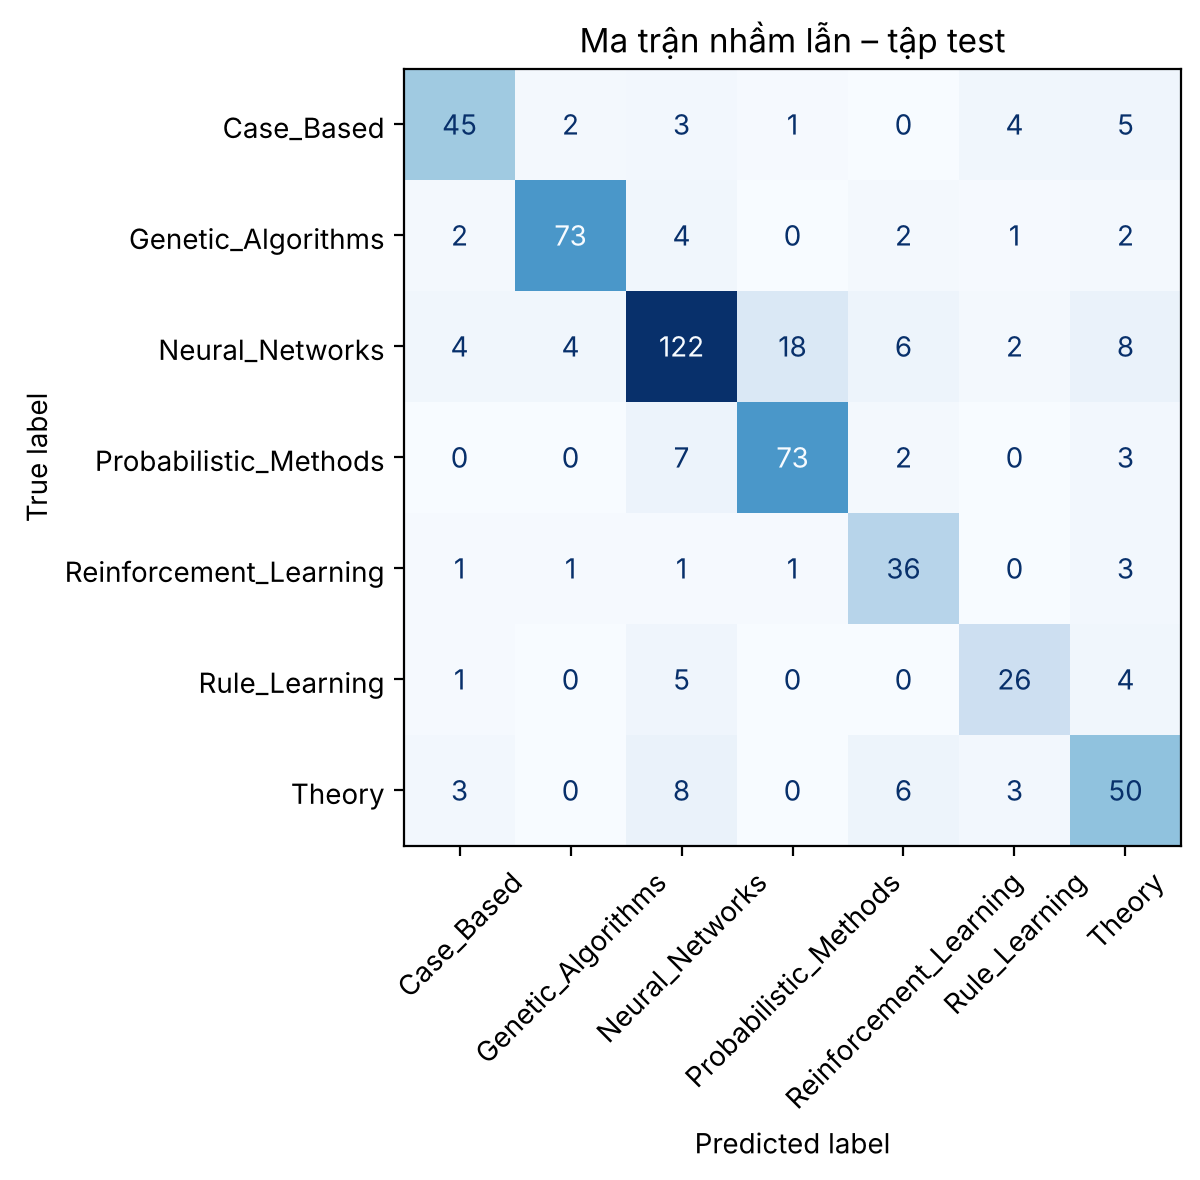

In [8]:
top_name = table.loc[table["Mô hình"] != "Baseline (không tiền xử lý)", "Mô hình"].iloc[0]
top_model = best[top_name]
y_pred = top_model.predict(X_test)
print(top_name)
print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=class_names,
                                        xticks_rotation=45, cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Ma trận nhầm lẫn – tập test")
plt.tight_layout()
plt.show()

## 7. Kết luận

| Mô hình | Accuracy | F1-macro |
|---|---|---|
| Baseline, không tiền xử lý | 0,753 | 0,733 |
| **SelectKBest(chi², k=572) + Normalizer + oversampling + LinearSVC** | **0,784** | **0,776** |
| Cùng pipeline, bỏ oversampling | 0,775 | 0,751 |

- **Tiền xử lý giúp tăng F1-macro 4,3 điểm** (0,733 → 0,776) so với baseline.
- **Oversampling góp khoảng 2,5 điểm**, chủ yếu nhờ recall của các lớp nhỏ, với điều kiện chỉ áp dụng trên tập train.
- **Normalizer hợp với dữ liệu từ nhị phân hơn StandardScaler:** hai cấu hình StandardScaler chỉ ngang baseline (~0,74).
- **Lỗi phổ biến nhất:** Neural_Networks bị nhầm thành Probabilistic_Methods (18/164 bài), nhiều khả năng vì hai chủ đề dùng chung nhiều từ vựng.